In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

DATA_PATH = Path("../csv_source_files")

sns.set_style("whitegrid")

In [3]:
# Province-level datasets
province_cereal_df = pd.read_csv(
    DATA_PATH / "02_cereal_production_by_province_2024_25.csv"
)

province_cash_df = pd.read_csv(
    DATA_PATH / "05_major_cash_crops_by_province_2024_25.csv"
)

province_vegetable_df = pd.read_csv(
    DATA_PATH / "11_fresh_vegetables_by_province_2024_25.csv"
)

# District-level dataset
district_cereal_df = pd.read_csv(
    DATA_PATH / "03_cereal_production_by_district_2024_25.csv"
)

In [4]:
datasets = {
    "Province Cereal": province_cereal_df,
    "Province Cash Crops": province_cash_df,
    "Province Vegetables": province_vegetable_df,
    "District Cereal": district_cereal_df
}

for name, df in datasets.items():
    print(f"{name}: {df.shape}")

Province Cereal: (48, 4)
Province Cash Crops: (24, 6)
Province Vegetables: (7, 5)
District Cereal: (85, 7)


In [5]:
for name, df in datasets.items():
    print(f"\n{'=' * 50}")
    print(name)
    print('=' * 50)

    display(df.head())
    print("\nColumns:", df.columns.tolist())
    print("\nData types:")
    print(df.dtypes)


Province Cereal


,Fiscal_Year,Province,Crop,Production_Mt
0,2024/25,Koshi,Buckwheat,4775.0
1,2024/25,Madhesh,Buckwheat,NaN
2,2024/25,Bagmati,Buckwheat,3260.0
3,2024/25,Gandaki,Buckwheat,1808.0
4,2024/25,Lumbini,Buckwheat,649.0



Columns: ['Fiscal_Year', 'Province', 'Crop', 'Production_Mt']

Data types:
Fiscal_Year          str
Province             str
Crop                 str
Production_Mt    float64
dtype: object

Province Cash Crops


,Fiscal_Year,Province,Crop,Area_Ha,Production_Mt,Yield_Mt_per_Ha
0,2024/25,Koshi,Potato,66607,1090527,16.37
1,2024/25,Madhesh,Potato,35559,527138,14.82
2,2024/25,Bagmati,Potato,39671,742637,19.09
3,2024/25,Gandaki,Potato,20476,374605,18.29
4,2024/25,Lumbini,Potato,27225,438707,16.11



Columns: ['Fiscal_Year', 'Province', 'Crop', 'Area_Ha', 'Production_Mt', 'Yield_Mt_per_Ha']

Data types:
Fiscal_Year            str
Province               str
Crop                   str
Area_Ha              int64
Production_Mt        int64
Yield_Mt_per_Ha    float64
dtype: object

Province Vegetables


,Fiscal_Year,Province,Area_Ha,Production_Mt,Yield_Mt_per_Ha
0,2024/25,Koshi,53062,831131,15.66
1,2024/25,Madhesh,101252,1385823,13.69
2,2024/25,Bagmati,53700,896234,16.69
3,2024/25,Gandaki,31499,340610,10.81
4,2024/25,Lumbini,53858,668405,12.41



Columns: ['Fiscal_Year', 'Province', 'Area_Ha', 'Production_Mt', 'Yield_Mt_per_Ha']

Data types:
Fiscal_Year            str
Province               str
Area_Ha              int64
Production_Mt        int64
Yield_Mt_per_Ha    float64
dtype: object

District Cereal


,Fiscal_Year,Province,District,Area_Ha,Production_Mt,Yield_Mt_per_Ha,Row_Type
0,2024/25,KOSHI,TAPLEJUNG,21673,63863,2.95,District
1,2024/25,KOSHI,SANKHUWASABHA,30542,72264,2.37,District
2,2024/25,KOSHI,SOLUKHUMBU,20336,43610,2.14,District
3,2024/25,KOSHI,PANCHTHAR,34075,103681,3.04,District
4,2024/25,KOSHI,ILLAM,51207,184964,3.61,District



Columns: ['Fiscal_Year', 'Province', 'District', 'Area_Ha', 'Production_Mt', 'Yield_Mt_per_Ha', 'Row_Type']

Data types:
Fiscal_Year            str
Province               str
District               str
Area_Ha              int64
Production_Mt        int64
Yield_Mt_per_Ha    float64
Row_Type               str
dtype: object


In [6]:
for name, df in datasets.items():
    print(f"\n{'=' * 45}")
    print(name)
    print('=' * 45)

    print("Missing values:")
    print(df.isnull().sum())

    print("\nDuplicate rows:", df.duplicated().sum())

    if "Province" in df.columns:
        print("\nUnique provinces:", df["Province"].nunique())

    if "Crop" in df.columns:
        print("Unique crops:", df["Crop"].nunique())

    if "Row_Type" in df.columns:
        print("\nRow types:")
        print(df["Row_Type"].value_counts(dropna=False))


Province Cereal
Missing values:
Fiscal_Year      0
Province         0
Crop             0
Production_Mt    1
dtype: int64

Duplicate rows: 0

Unique provinces: 8
Unique crops: 6

Province Cash Crops
Missing values:
Fiscal_Year        0
Province           0
Crop               0
Area_Ha            0
Production_Mt      0
Yield_Mt_per_Ha    0
dtype: int64

Duplicate rows: 0

Unique provinces: 8
Unique crops: 3

Province Vegetables
Missing values:
Fiscal_Year        0
Province           0
Area_Ha            0
Production_Mt      0
Yield_Mt_per_Ha    0
dtype: int64

Duplicate rows: 0

Unique provinces: 7

District Cereal
Missing values:
Fiscal_Year        0
Province           0
District           0
Area_Ha            0
Production_Mt      0
Yield_Mt_per_Ha    0
Row_Type           0
dtype: int64

Duplicate rows: 0

Unique provinces: 15

Row types:
Row_Type
District             77
Province Subtotal     8
Name: count, dtype: int64


In [7]:
# Find missing cereal production record
display(
    province_cereal_df[
        province_cereal_df["Production_Mt"].isna()
    ]
)

# Check province names in each dataset
for name, df in datasets.items():
    print(f"\n{name}")
    print(sorted(df["Province"].unique()))

,Fiscal_Year,Province,Crop,Production_Mt
1,2024/25,Madhesh,Buckwheat,NaN



Province Cereal
['Bagmati', 'Gandaki', 'Karnali', 'Koshi', 'Lumbini', 'Madhesh', 'Nepal', 'Sudurpashchim']

Province Cash Crops
['Bagmati', 'Gandaki', 'Karnali', 'Koshi', 'Lumbini', 'Madhesh', 'Nepal', 'Sudurpashchim']

Province Vegetables
['Bagmati', 'Gandaki', 'Karnali', 'Koshi', 'Lumbini', 'Madhesh', 'Sudurpschhim']

District Cereal
['BAGMATI', 'BAGMATI SUBTOTAL', 'GANDAKI', 'GANDAKI SUBTOTAL', 'KARNALI', 'KARNALI SUBTOTAL', 'KOSHI', 'KOSHI SUBTOTAL', 'LUMBINI', 'LUMBINI SUBTOTAL', 'MADHESH', 'MADHESH SUBTOTAL', 'NEPAL', 'SUDURPASHCHIM', 'SUDURPASHCHIM SUBTOTAL']


In [8]:
# Exclude national-level Nepal records
province_cereal_df = province_cereal_df[
    province_cereal_df["Province"] != "Nepal"
].copy()

province_cash_df = province_cash_df[
    province_cash_df["Province"] != "Nepal"
].copy()

# Standardize province name
province_vegetable_df["Province"] = (
    province_vegetable_df["Province"]
    .replace({"Sudurpschhim": "Sudurpashchim"})
)

# Keep only district-level records
district_cereal_df = district_cereal_df[
    district_cereal_df["Row_Type"] == "District"
].copy()

In [9]:
for name, df in {
    "Province Cereal": province_cereal_df,
    "Province Cash Crops": province_cash_df,
    "Province Vegetables": province_vegetable_df,
    "District Cereal": district_cereal_df
}.items():
    print(f"{name}: {df.shape}")
    print("Provinces:", sorted(df["Province"].unique()))
    print()

Province Cereal: (42, 4)
Provinces: ['Bagmati', 'Gandaki', 'Karnali', 'Koshi', 'Lumbini', 'Madhesh', 'Sudurpashchim']

Province Cash Crops: (21, 6)
Provinces: ['Bagmati', 'Gandaki', 'Karnali', 'Koshi', 'Lumbini', 'Madhesh', 'Sudurpashchim']

Province Vegetables: (7, 5)
Provinces: ['Bagmati', 'Gandaki', 'Karnali', 'Koshi', 'Lumbini', 'Madhesh', 'Sudurpashchim']

District Cereal: (77, 7)
Provinces: ['BAGMATI', 'GANDAKI', 'KARNALI', 'KOSHI', 'LUMBINI', 'MADHESH', 'SUDURPASHCHIM']



In [10]:
buckwheat_df = province_cereal_df[
    province_cereal_df["Crop"] == "Buckwheat"
].copy()

display(
    buckwheat_df[
        ["Province", "Crop", "Production_Mt"]
    ].sort_values("Production_Mt", ascending=False)
)

,Province,Crop,Production_Mt
0,Koshi,Buckwheat,4775.0
2,Bagmati,Buckwheat,3260.0
5,Karnali,Buckwheat,3095.0
3,Gandaki,Buckwheat,1808.0
4,Lumbini,Buckwheat,649.0
6,Sudurpashchim,Buckwheat,49.0
1,Madhesh,Buckwheat,NaN


### Province Cereal Production

In [11]:
province_cereal_total = (
    province_cereal_df
    .groupby("Province")["Production_Mt"]
    .sum()
    .reset_index()
    .rename(columns={"Production_Mt": "Total_Production_Mt"})
    .sort_values("Total_Production_Mt", ascending=False)
)

display(province_cereal_total)

,Province,Total_Production_Mt
3,Koshi,2862429.0
4,Lumbini,2443867.0
5,Madhesh,2382330.0
0,Bagmati,1361750.0
6,Sudurpashchim,1109544.0
1,Gandaki,905170.0
2,Karnali,542030.0


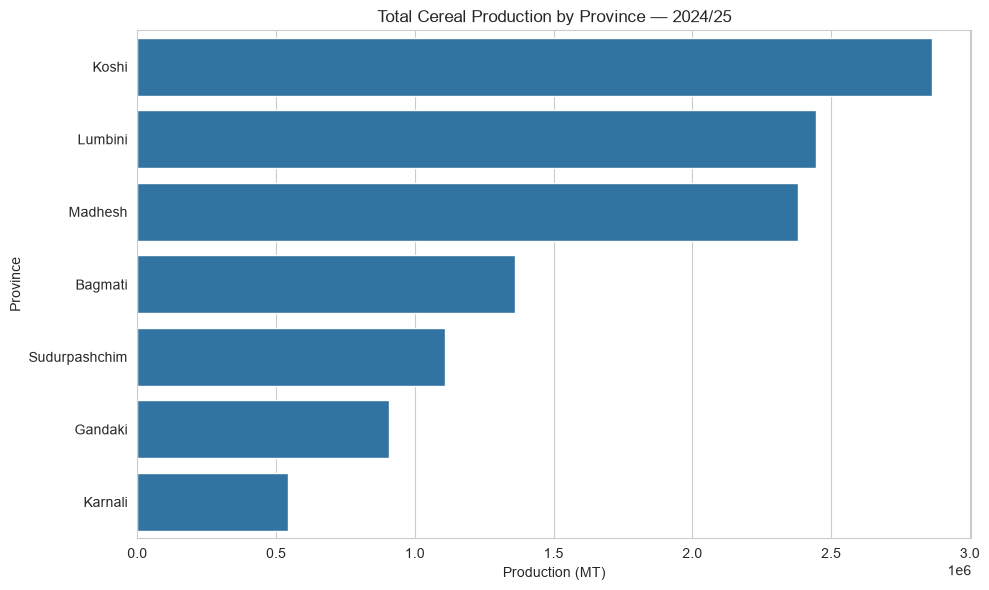

In [12]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=province_cereal_total,
    x="Total_Production_Mt",
    y="Province"
)

plt.title("Total Cereal Production by Province — 2024/25")
plt.xlabel("Production (MT)")
plt.ylabel("Province")
plt.tight_layout()
plt.show()

In [ ]:
# Contribution percentage of each province to the total cereal production
total_cereal_production = province_cereal_total["Total_Production_Mt"].sum()

province_cereal_total["Contribution_Pct"] = (
    province_cereal_total["Total_Production_Mt"]
    / total_cereal_production
    * 100
)

display(province_cereal_total)

,Province,Total_Production_Mt,Contribution_Pct
3,Koshi,2862429.0,24.660975
4,Lumbini,2443867.0,21.054896
5,Madhesh,2382330.0,20.524730
0,Bagmati,1361750.0,11.732023
6,Sudurpashchim,1109544.0,9.559167
1,Gandaki,905170.0,7.798403
2,Karnali,542030.0,4.669806


In [19]:
# Calculate total production for each province
province_crop_totals = (
    province_cereal_df
    .groupby(["Province", "Crop"])["Production_Mt"]
    .sum()
    .reset_index()
)

# Calculate each crop's contribution within its province
province_crop_totals["Contribution_Pct"] = (
    province_crop_totals["Production_Mt"]
    / province_crop_totals.groupby("Province")["Production_Mt"].transform("sum")
    * 100
)

# Select the highest-producing crop in each province
top_crop_by_province = (
    province_crop_totals
    .sort_values(["Province", "Production_Mt"], ascending=[True, False])
    .groupby("Province")
    .head(1)
    .sort_values("Production_Mt", ascending=False)
    .reset_index(drop=True)
)

display(top_crop_by_province)

,Province,Crop,Production_Mt,Contribution_Pct
0,Madhesh,Paddy,1480830.0,62.158895
1,Koshi,Paddy,1466518.0,51.233341
2,Lumbini,Paddy,1364031.0,55.814453
3,Bagmati,Maize,657019.0,48.248137
4,Sudurpashchim,Paddy,636212.0,57.339952
5,Gandaki,Maize,393313.0,43.451838
6,Karnali,Maize,217304.0,40.090770


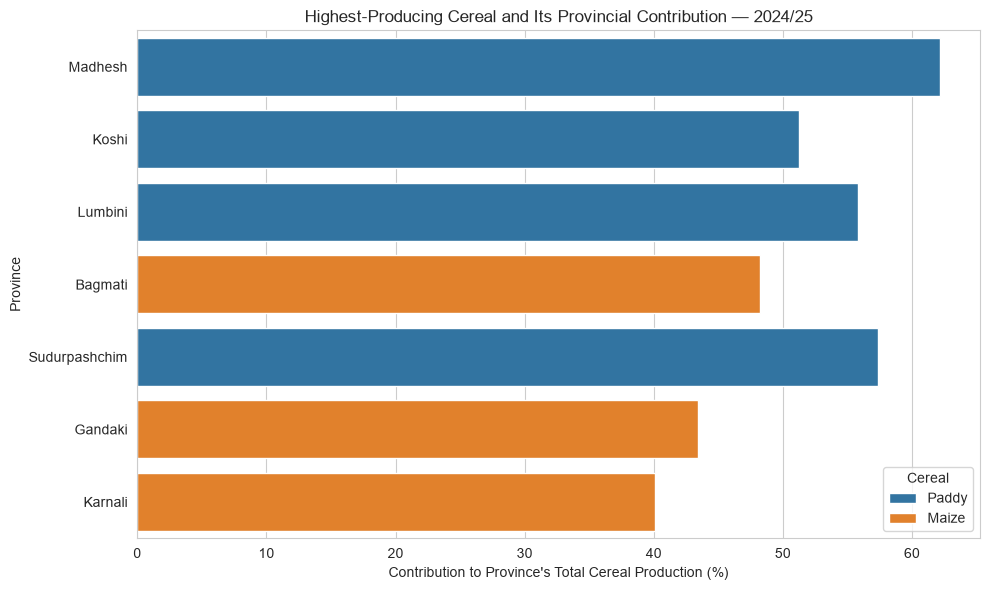

In [20]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_crop_by_province,
    x="Contribution_Pct",
    y="Province",
    hue="Crop",
    dodge=False
)

plt.title("Highest-Producing Cereal and Its Provincial Contribution — 2024/25")
plt.xlabel("Contribution to Province's Total Cereal Production (%)")
plt.ylabel("Province")
plt.legend(title="Cereal")
plt.tight_layout()
plt.show()

### Major Cash Crops by Province

In [21]:
province_cash_total = (
    province_cash_df
    .groupby("Province")["Production_Mt"]
    .sum()
    .reset_index()
    .rename(columns={"Production_Mt": "Total_Production_Mt"})
    .sort_values("Total_Production_Mt", ascending=False)
)

display(province_cash_total)

,Province,Total_Production_Mt
5,Madhesh,2309771
3,Koshi,1485824
0,Bagmati,781564
4,Lumbini,761109
6,Sudurpashchim,672425
1,Gandaki,399919
2,Karnali,238152


In [22]:
total_cash_production = province_cash_total["Total_Production_Mt"].sum()

province_cash_total["Contribution_Pct"] = (
    province_cash_total["Total_Production_Mt"]
    / total_cash_production
    * 100
)

display(province_cash_total)

,Province,Total_Production_Mt,Contribution_Pct
5,Madhesh,2309771,34.739855
3,Koshi,1485824,22.347372
0,Bagmati,781564,11.755027
4,Lumbini,761109,11.447376
6,Sudurpashchim,672425,10.113534
1,Gandaki,399919,6.014938
2,Karnali,238152,3.581899


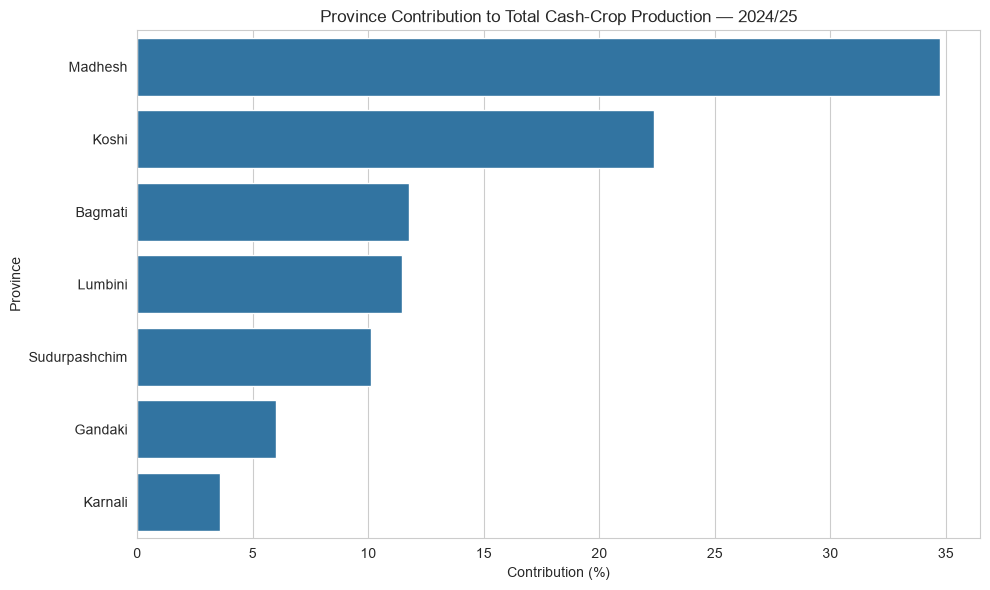

In [23]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=province_cash_total,
    x="Contribution_Pct",
    y="Province"
)

plt.title("Province Contribution to Total Cash-Crop Production — 2024/25")
plt.xlabel("Contribution (%)")
plt.ylabel("Province")
plt.tight_layout()
plt.show()

In [24]:
province_cash_crop = (
    province_cash_df
    .groupby(["Province", "Crop"])["Production_Mt"]
    .sum()
    .reset_index()
)

# Calculate each crop's share within its province
province_cash_crop["Contribution_Pct"] = (
    province_cash_crop["Production_Mt"]
    / province_cash_crop.groupby("Province")["Production_Mt"].transform("sum")
    * 100
)

# Select the highest-producing crop in each province
top_cash_crop_by_province = (
    province_cash_crop
    .sort_values(
        ["Province", "Production_Mt"],
        ascending=[True, False]
    )
    .groupby("Province")
    .head(1)
    .sort_values("Production_Mt", ascending=False)
    .reset_index(drop=True)
)

display(top_cash_crop_by_province)

,Province,Crop,Production_Mt,Contribution_Pct
0,Madhesh,Sugarcane,1723361,74.611769
1,Koshi,Potato,1090527,73.395436
2,Bagmati,Potato,742637,95.019346
3,Lumbini,Potato,438707,57.640496
4,Gandaki,Potato,374605,93.670218
5,Sudurpashchim,Sugarcane,361880,53.817154
6,Karnali,Potato,220799,92.713477


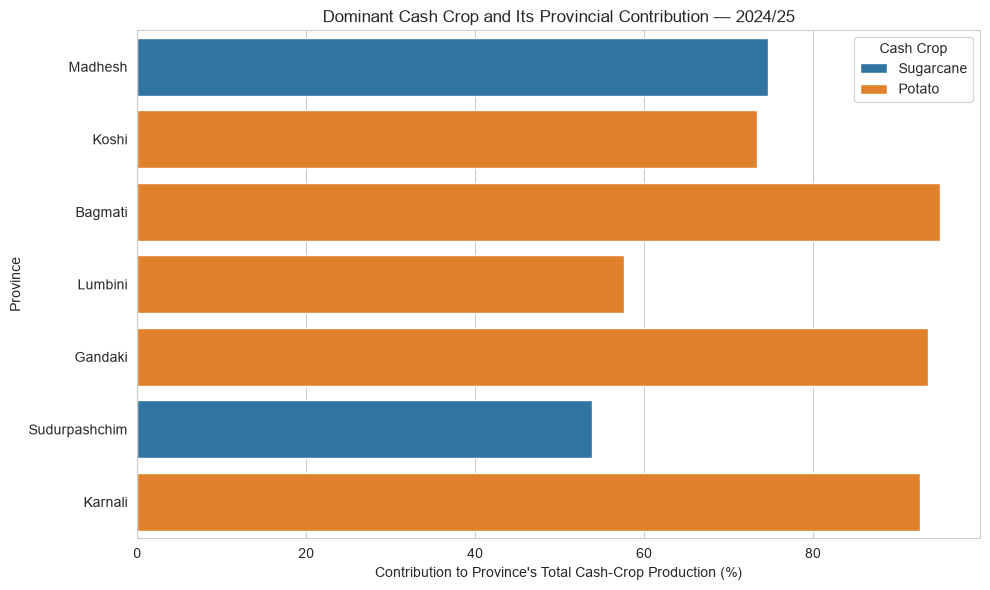

In [25]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_cash_crop_by_province,
    x="Contribution_Pct",
    y="Province",
    hue="Crop",
    dodge=False
)

plt.title("Dominant Cash Crop and Its Provincial Contribution — 2024/25")
plt.xlabel("Contribution to Province's Total Cash-Crop Production (%)")
plt.ylabel("Province")
plt.legend(title="Cash Crop")
plt.tight_layout()
plt.show()

In [26]:
cash_crop_yield = (
    province_cash_df
    .groupby(["Province", "Crop"])["Yield_Mt_per_Ha"]
    .mean()
    .reset_index()
)

display(cash_crop_yield)

,Province,Crop,Yield_Mt_per_Ha
0,Bagmati,Oilseed,1.18
1,Bagmati,Potato,19.09
2,Bagmati,Sugarcane,20.71
3,Gandaki,Oilseed,1.06
4,Gandaki,Potato,18.29
5,Gandaki,Sugarcane,40.70
6,Karnali,Oilseed,0.98
7,Karnali,Potato,17.30
8,Karnali,Sugarcane,5.33
9,Koshi,Oilseed,1.23


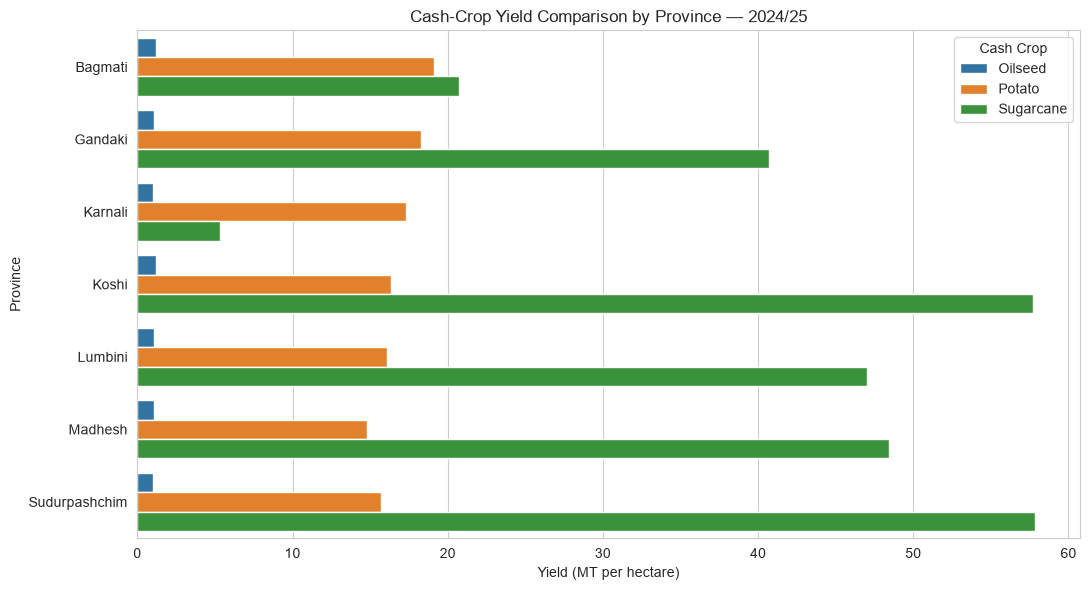

In [27]:
plt.figure(figsize=(11, 6))

sns.barplot(
    data=cash_crop_yield,
    x="Yield_Mt_per_Ha",
    y="Province",
    hue="Crop"
)

plt.title("Cash-Crop Yield Comparison by Province — 2024/25")
plt.xlabel("Yield (MT per hectare)")
plt.ylabel("Province")
plt.legend(title="Cash Crop")
plt.tight_layout()
plt.show()

### Fresh Vegetables by Province